(sec-11-1)=
# 11.1 Cardiac Electrophysiology and the ECG Waveform

Before processing an ECG, I want to connect its waves to the electrical activity that produces them. The trace is a voltage difference measured between electrodes. Its shape depends on both the activity spreading through the heart and the direction from which a lead observes that activity.

We will follow the activation sequence, connect it to the P wave, QRS complex, and T wave, and then work through the lead relationships. The mathematical models help explain these connections, but they simplify a heart whose anatomy and electrical activity are three-dimensional.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal
from scipy.interpolate import PchipInterpolator

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-11-1-1)=
## 11.1.1 The Conduction System and the Cardiac Action Potential

### The activation sequence

Each heartbeat starts in the **sinoatrial (SA) node**, a small cluster of specialized cells in the wall of the right atrium near the entrance of the superior vena cava. SA node cells have no stable resting potential. Their membrane potential drifts slowly upward after every beat until it reaches threshold and fires, so the node behaves as a relaxation oscillator. At rest it fires roughly 60 to 100 times per minute, and the autonomic nervous system speeds it up (sympathetic drive) or slows it down (vagal drive). This modulation is what heart rate variability measures in Section 19.2.

From the SA node the wave of depolarization spreads through both atria, cell to cell through gap junctions, at roughly 0.5 to 1 m/s. The atria and ventricles are electrically insulated from each other by a fibrous ring, and the only normal path across it is the **atrioventricular (AV) node**. Conduction through the AV node is slow, and this slowness is useful: it delays ventricular activation by about a tenth of a second so that the atria can finish pushing blood into the ventricles. Below the AV node the impulse enters the **bundle of His**, divides into the left and right **bundle branches** along the interventricular septum, and reaches the **Purkinje fibers**, a fast network (2 to 4 m/s) that distributes it over the inner (endocardial) surface of both ventricles. The ventricular muscle then depolarizes from endocardium to epicardium. Thanks to the Purkinje network, the whole ventricular mass is activated within about 80 to 100 ms, which is why the QRS complex is the narrowest and steepest part of the ECG.

### The ventricular action potential

The membrane potential of a ventricular muscle cell follows a characteristic time course with five conventional phases. The ionic mechanisms are summarized here only qualitatively; the membrane biophysics behind them is developed in [Section 1.2](../ch01_introduction/02_bioelectric_origins.ipynb).

- **Phase 4 (rest).** The membrane sits near $-85$ to $-90$ mV, close to the potassium equilibrium potential, because the resting membrane is far more permeable to K$^+$ than to other ions.
- **Phase 0 (rapid upstroke).** When a neighboring cell pulls the membrane to threshold, fast sodium channels open and Na$^+$ rushes in. The potential rises to about $+20$ to $+30$ mV in one or two milliseconds.
- **Phase 1 (early repolarization).** Sodium channels inactivate and a transient outward potassium current produces a small notch.
- **Phase 2 (plateau).** L-type calcium channels let Ca$^{2+}$ in while potassium leaks out. The two currents nearly balance, and the potential stays near 0 mV for 150 to 250 ms. The calcium entry triggers contraction.
- **Phase 3 (repolarization).** Calcium channels close, delayed-rectifier potassium currents grow, and the membrane returns to rest.

Pacemaker cells of the SA and AV nodes look different. They lack a flat phase 4; instead the potential creeps from about $-60$ mV toward a threshold near $-40$ mV (the slow diastolic depolarization), and their upstroke is carried mainly by calcium, so it is slower and smaller. The slope of the diastolic ramp sets the firing rate, and it is this slope that the autonomic nerves adjust.

The figure below draws both shapes schematically. The curves are smooth interpolations through typical values, not the output of an ionic model, but they capture the features that matter for the ECG: a fast upstroke, a long plateau and a slower repolarization in the ventricle, and a ramp-and-fire cycle in the pacemaker.

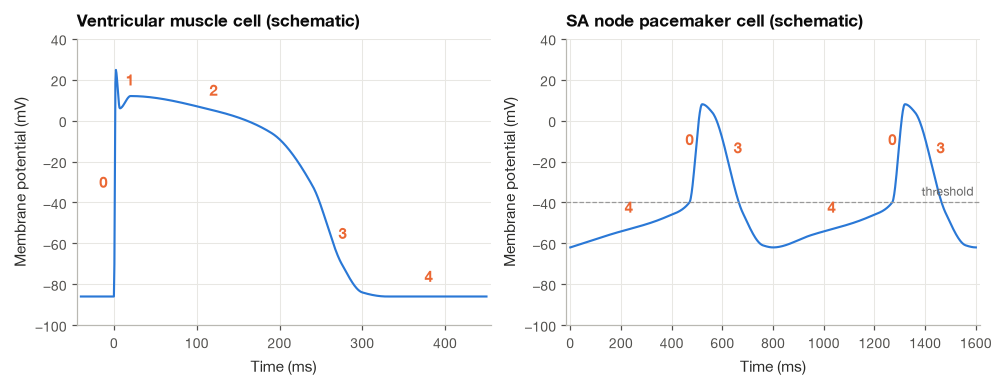

In [2]:
t_ven = np.linspace(-40, 450, 800)                           # ms
ven_knots = np.array([[-40, -86], [0, -86], [2, 25], [7, 6], [20, 12], [120, 5],
                      [190, -6], [240, -32], [275, -70], [300, -84], [330, -86], [450, -86]])
v_ven = PchipInterpolator(ven_knots[:, 0], ven_knots[:, 1])(t_ven)

cycle = np.array([[0, -62], [150, -56], [380, -47], [470, -40], [520, 8], [560, 4],
                  [680, -45], [760, -61], [800, -62]])       # one 800 ms cycle (75 bpm)
sa_knots = np.vstack([cycle[:-1], cycle + [800, 0]])
t_sa = np.linspace(0, 1600, 900)
v_sa = PchipInterpolator(sa_knots[:, 0], sa_knots[:, 1])(t_sa)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
ax = axes[0]
ax.plot(t_ven, v_ven, color=C[0])
for label, (x, y), (dx, dy) in [("0", (1, -30), (-14, 0)), ("1", (7, 6), (12, 14)),
                                ("2", (120, 5), (0, 10)), ("3", (262, -55), (14, 0)),
                                ("4", (380, -86), (0, 10))]:
    ax.text(x + dx, y + dy, label, fontsize=10, color=C[1], fontweight="bold", ha="center", va="center")
ax.set(xlabel="Time (ms)", ylabel="Membrane potential (mV)", ylim=(-100, 40),
       title="Ventricular muscle cell (schematic)")

ax = axes[1]
ax.plot(t_sa, v_sa, color=C[0])
for label, x, y in [("4", 230, -45), ("0", 470, -12), ("3", 660, -16),
                    ("4", 1030, -45), ("0", 1270, -12), ("3", 1460, -16)]:
    ax.text(x, y, label, fontsize=10, color=C[1], fontweight="bold", ha="center")
ax.axhline(-40, color="0.6", lw=0.8, ls="--")
ax.text(1590, -38, "threshold", ha="right", va="bottom", fontsize=8, color="0.4")
ax.set(xlabel="Time (ms)", ylabel="Membrane potential (mV)", ylim=(-100, 40),
       title="SA node pacemaker cell (schematic)")
plt.show()

### From cells to the body surface

A cell at rest or a cell sitting on its plateau produces no external field by itself. What the body-surface electrodes see is the *boundary* between active and inactive tissue, because only there do intracellular potential differences drive currents through the surrounding volume conductor. This one idea explains the main features of the ECG:

| ECG feature | Underlying event |
|---|---|
| P wave | depolarization wavefront crossing the atria |
| PR segment | slow conduction through the AV node and His–Purkinje system (too little tissue to be visible) |
| QRS complex | depolarization wavefront crossing the ventricles |
| ST segment | ventricles on their plateau (phase 2): nearly all cells at a similar potential, little net current |
| T wave | ventricular repolarization (phase 3) |

Atrial repolarization produces a small wave too, but it coincides with the QRS complex and is normally hidden.

One feature of the table deserves an explanation. Repolarization is the opposite of depolarization, so we might expect the T wave to have the opposite polarity from the QRS complex. In most healthy leads it does not. The reason is that epicardial cells have shorter action potentials than endocardial cells, so although depolarization runs from endocardium to epicardium, repolarization runs mostly the other way. Reversing both the sign of the process and its direction leaves the polarity of the surface signal unchanged, and the T wave ends up pointing the same way as the dominant QRS deflection.

(sec-11-1-2)=
## 11.1.2 The Heart as a Current Dipole

### Potential of a dipole in a volume conductor

Consider a small patch of tissue at the edge of an advancing wavefront. Current leaves the intracellular space on one side of the boundary and re-enters on the other, so the patch acts like a current source $+I$ and a current sink $-I$ separated by a short distance. In an infinite, homogeneous medium of conductivity $\sigma$ (S/m), a single point source of current $I$ produces the potential

$$
\Phi(\mathbf{r}) = \frac{I}{4\pi\sigma\,|\mathbf{r} - \mathbf{r}_s|},
$$

This first expression is an idealized volume-conductor model. The point $\mathbf{r}_s$ locates a current source and $\mathbf{r}$ locates the observation point; their distance is $|\mathbf{r}-\mathbf{r}_s|$. The current is $I$ and conductivity is $\sigma$. Holding the other terms fixed, doubling the distance halves the predicted potential. A cardiac source needs a source-and-sink description, which is why the next step uses a difference of two such terms.

where $\mathbf{r}_s$ is the source location. This follows from spreading the current evenly over a sphere of radius $R$ (current density $I/4\pi R^2$), using Ohm's law $\mathbf{E} = \mathbf{J}/\sigma$ and integrating the field from infinity.

**Step 1: superpose a source and a sink.** Place $+I$ at $\mathbf{r}_0 + \mathbf{d}/2$ and $-I$ at $\mathbf{r}_0 - \mathbf{d}/2$, and write $\mathbf{R} = \mathbf{r} - \mathbf{r}_0$ for the vector from the pair to the observation point. Superposition gives

$$
\Phi(\mathbf{r}) = \frac{I}{4\pi\sigma}\left(\frac{1}{|\mathbf{R} - \mathbf{d}/2|} - \frac{1}{|\mathbf{R} + \mathbf{d}/2|}\right).
$$

**Step 2: expand for a distant observer.** When $|\mathbf{d}| \ll |\mathbf{R}|$, a first-order Taylor expansion of $1/|\mathbf{R} - \mathbf{a}|$ around $\mathbf{a} = \mathbf{0}$ gives

$$
\frac{1}{|\mathbf{R} - \mathbf{a}|} \approx \frac{1}{|\mathbf{R}|} - \mathbf{a}\cdot\nabla\!\left(\frac{1}{|\mathbf{R}|}\right) = \frac{1}{|\mathbf{R}|} + \frac{\mathbf{a}\cdot\mathbf{R}}{|\mathbf{R}|^3},
$$

because the gradient of $1/|\mathbf{R}|$ is $-\mathbf{R}/|\mathbf{R}|^3$.

**Step 3: subtract.** Using $\mathbf{a} = +\mathbf{d}/2$ for the first term and $\mathbf{a} = -\mathbf{d}/2$ for the second, the $1/|\mathbf{R}|$ terms cancel and the two first-order terms add:

(eq-11-1)=
\begin{equation*}
\begin{aligned}
\Phi(\mathbf{r}) &\approx \frac{I}{4\pi\sigma}\left(\frac{\mathbf{d}\cdot\mathbf{R}}{2|\mathbf{R}|^3} + \frac{\mathbf{d}\cdot\mathbf{R}}{2|\mathbf{R}|^3}\right) \\
&= \frac{\mathbf{p}\cdot\mathbf{R}}{4\pi\sigma\,|\mathbf{R}|^3}, \qquad \mathbf{p} = I\,\mathbf{d}.
\end{aligned} \tag{11.1}
\end{equation*}

The vector $\mathbf{p}$, measured in A·m, is the **current dipole moment**. The potential falls off as $1/R^2$ rather than $1/R$ because the source and sink almost cancel, and it depends on the angle between $\mathbf{p}$ and the direction to the observer: positive in front of the dipole, negative behind it, zero on the plane perpendicular to it.

At any instant, the many small dipoles along the activation front add vectorially. Seen from far away, their sum behaves like a single **equivalent dipole**, the *heart vector* $\mathbf{p}(t)$. As the wavefront travels through the atria, the septum, the apex and finally the base of the ventricles, the heart vector changes both its length and its direction. The ECG is the record of that rotating, pulsing arrow.

Before using equation [(11.1)](#eq-11-1) we check numerically how good the dipole approximation is. We take a source and sink of 1 mA separated by 1 cm, a conductivity of 0.2 S/m (a round value of the order reported for average torso tissue) and observers at increasing distance, $30^\circ$ off the dipole axis.

In [3]:
sigma = 0.2                          # S/m
I_src = 1e-3                         # A
d = np.array([0.01, 0.0, 0.0])       # m, source-sink separation
p = I_src * d                        # dipole moment (A m)


def monopole_potential(r, r_s, current, sigma):
    """Potential (V) of a point current source in an infinite homogeneous medium."""
    return current / (4 * np.pi * sigma * np.linalg.norm(r - r_s))


def dipole_potential(r, r0, p, sigma):
    """Far-field potential (V) of a current dipole, equation (17.1)."""
    R = r - r0
    return p @ R / (4 * np.pi * sigma * np.linalg.norm(R) ** 3)


angle = np.deg2rad(30)
rows = []
for dist_cm in [2, 5, 10, 20]:
    r = dist_cm / 100 * np.array([np.cos(angle), np.sin(angle), 0.0])
    exact = (monopole_potential(r, d / 2, I_src, sigma)
             + monopole_potential(r, -d / 2, -I_src, sigma))
    approx = dipole_potential(r, np.zeros(3), p, sigma)
    rows.append([dist_cm, 1e3 * exact, 1e3 * approx, 100 * abs(approx - exact) / abs(exact)])
print(pd.DataFrame(rows, columns=["distance (cm)", "exact (mV)", "dipole (mV)", "error (%)"])
      .round(4).to_string(index=False))

 distance (cm)  exact (mV)  dipole (mV)  error (%)
             2      8.8067       8.6145     2.1825
             5      1.3835       1.3783     0.3710
            10      0.3449       0.3446     0.0935
            20      0.0862       0.0861     0.0234


At 2 cm the approximation is off by a few percent; at the 10 to 20 cm separating the heart from a limb electrode the error is a small fraction of a percent, and it shrinks roughly as $(|\mathbf{d}|/R)^2$. The magnitudes are also realistic: a millivolt-level signal at 10 cm, which is what an ECG amplifier sees.

### Lead voltage as a projection

An ECG lead measures the potential difference between two electrodes, $A$ and $B$. Applying equation [(11.1)](#eq-11-1) at each electrode, with the heart vector located at $\mathbf{r}_0$,

(eq-11-2)=
\begin{equation*}
\begin{aligned}
V_{AB}(t) &= \Phi(\mathbf{r}_A, t) - \Phi(\mathbf{r}_B, t) \\
&= \mathbf{p}(t)\cdot\frac{\mathbf{r}_A - \mathbf{r}_0}{4\pi\sigma|\mathbf{r}_A - \mathbf{r}_0|^3} - \mathbf{p}(t)\cdot\frac{\mathbf{r}_B - \mathbf{r}_0}{4\pi\sigma|\mathbf{r}_B - \mathbf{r}_0|^3} \\
&= \mathbf{p}(t)\cdot\mathbf{l}_{AB}.
\end{aligned} \tag{11.2}
\end{equation*}

The second line uses the fact that the dot product is linear, so $\mathbf{p}(t)$ can be pulled out of both terms. The vector $\mathbf{l}_{AB}$ collecting everything else is the **lead vector**. It depends only on the geometry of the electrodes and the conductor, not on time. Equation [(11.2)](#eq-11-2) is the most useful single equation in electrocardiography: **every lead is the projection of the same heart vector onto a different, fixed direction**, scaled by the length of the lead vector. A lead whose vector is parallel to the heart vector at some instant shows a large positive deflection, an antiparallel lead shows a large negative one, and a perpendicular lead shows almost nothing.

The real torso is finite and inhomogeneous (lungs conduct poorly, blood well), so its lead vectors are not given by the simple formula in [(11.2)](#eq-11-2). Burger and van Milaan measured them in torso models and found that they differ noticeably from the idealized ones {cite:p}`malmivuo1995`. What survives is the *linearity*: as long as the tissue behaves as a linear resistive conductor at ECG frequencies, $V_{AB} = \mathbf{p}\cdot\mathbf{l}_{AB}$ holds with some fixed $\mathbf{l}_{AB}$, and that is enough for everything that follows.

(sec-11-1-3)=
## 11.1.3 Limb Leads, Augmented Leads and Precordial Leads

### Einthoven's limb leads

Willem Einthoven placed electrodes on the right arm (RA), left arm (LA) and left leg (LL). The limbs act as extensions of the torso, so these electrodes sample the potentials at the shoulders and the groin, which we write $\Phi_R$, $\Phi_L$ and $\Phi_F$ (F for foot). A fourth electrode on the right leg serves as the reference for the amplifier's common mode and does not enter any lead. The three **limb leads** are defined as

(eq-11-3)=
\begin{equation*}
\text{I} = \Phi_L - \Phi_R, \qquad \text{II} = \Phi_F - \Phi_R, \qquad \text{III} = \Phi_F - \Phi_L. \tag{11.3}
\end{equation*}

Adding leads I and III, the $\Phi_L$ terms cancel:

(eq-11-4)=
\begin{equation*}
\begin{aligned}
\text{I} + \text{III} &= (\Phi_L - \Phi_R) + (\Phi_F - \Phi_L) \\
&= \Phi_F - \Phi_R = \text{II}.
\end{aligned} \tag{11.4}
\end{equation*}

This is **Einthoven's law**. It is nothing more than Kirchhoff's voltage law around the loop RA → LA → LL → RA, so it holds at every instant, for any source and any torso. It also tells us that the three limb leads carry only two independent signals.

**Einthoven's triangle.** To relate the limb leads to the heart vector, Einthoven idealized the three electrodes as the corners of an equilateral triangle in the frontal plane, with the heart at its center. In cardiology the frontal-plane angle is measured from the patient's left (lead I direction, $0^\circ$) and increases *clockwise* as seen by an observer facing the patient, so that $+90^\circ$ points toward the feet. With the dipole at the center and electrodes at equal distance $R$, equation [(11.2)](#eq-11-2) gives each lead vector as proportional to the difference of the electrode position vectors. For lead I this difference points from RA to LA, horizontally, at $0^\circ$; for lead II from RA to LL, at $+60^\circ$; for lead III from LA to LL, at $+120^\circ$. All three have the same length. Writing the heart vector as $\mathbf{p} = |\mathbf{p}|(\cos\theta, \sin\theta)$ in this convention and absorbing the common length into the amplitude,

(eq-11-5)=
\begin{equation*}
\text{I} = |\mathbf{p}|\cos\theta, \qquad \text{II} = |\mathbf{p}|\cos(\theta - 60^\circ), \qquad \text{III} = |\mathbf{p}|\cos(\theta - 120^\circ). \tag{11.5}
\end{equation*}

Einthoven's law is consistent with this picture. Using the sum-to-product identity $\cos a + \cos b = 2\cos\frac{a+b}{2}\cos\frac{a-b}{2}$,

$$
\cos\theta + \cos(\theta - 120^\circ) = 2\cos(\theta - 60^\circ)\cos 60^\circ = \cos(\theta - 60^\circ),
$$

so $\text{I} + \text{III} = \text{II}$ for every direction $\theta$.

### Wilson's central terminal

Bipolar leads measure the difference between two body sites. To approximate a *unipolar* potential at a single site we need a reference that stays close to zero throughout the cardiac cycle. Frank Wilson proposed joining RA, LA and LL through three equal resistors $R_W$ to a common node, the **Wilson central terminal** (WCT). The node draws no net current into the amplifier, so by Kirchhoff's current law the three resistor currents sum to zero:

(eq-11-6)=
\begin{equation*}
\frac{\Phi_R - \Phi_{W}}{R_W} + \frac{\Phi_L - \Phi_{W}}{R_W} + \frac{\Phi_F - \Phi_{W}}{R_W} = 0
\quad\Longrightarrow\quad \Phi_{W} = \frac{\Phi_R + \Phi_L + \Phi_F}{3}. \tag{11.6}
\end{equation*}

The WCT is the average of the three limb potentials. In the ideal triangle model the three limb potentials are projections of $\mathbf{p}$ onto three unit vectors $120^\circ$ apart, which sum to zero, so $\Phi_W = 0$ at every instant. In a real torso it is not exactly zero, but it varies much less than any single limb potential.

### Goldberger's augmented leads

Measuring each limb potential against the WCT gives the unipolar limb leads,

$$
V_R = \Phi_R - \Phi_W = \Phi_R - \frac{\Phi_R + \Phi_L + \Phi_F}{3} = \frac{2\Phi_R - \Phi_L - \Phi_F}{3}.
$$

These are small. Emanuel Goldberger noticed that if the electrode being measured is *disconnected* from the averaging network, the reference becomes the mean of the remaining two limbs, and the signal grows. The **augmented** lead for the right arm is

(eq-11-7)=
\begin{equation*}
\text{aVR} = \Phi_R - \frac{\Phi_L + \Phi_F}{2} = \frac{2\Phi_R - \Phi_L - \Phi_F}{2} = \frac{3}{2}\,V_R. \tag{11.7}
\end{equation*}

The last equality compares the numerators: both $V_R$ and aVR contain $2\Phi_R - \Phi_L - \Phi_F$, divided by 3 and 2 respectively, so aVR is exactly 50 % larger, hence "augmented." The other two follow by symmetry,

$$
\text{aVL} = \Phi_L - \frac{\Phi_R + \Phi_F}{2}, \qquad \text{aVF} = \Phi_F - \frac{\Phi_R + \Phi_L}{2}.
$$

Because all six frontal leads are built from only three potentials, the augmented leads can be computed from leads I and II. For aVR, note that $\text{I} + \text{II} = (\Phi_L - \Phi_R) + (\Phi_F - \Phi_R) = \Phi_L + \Phi_F - 2\Phi_R$, which is $-2$ times the numerator of [(11.7)](#eq-11-7). Repeating the bookkeeping for the other two leads,

(eq-11-8)=
\begin{equation*}
\text{aVR} = -\frac{\text{I} + \text{II}}{2}, \qquad
\text{aVL} = \text{I} - \frac{\text{II}}{2} = \frac{\text{I} - \text{III}}{2}, \qquad
\text{aVF} = \text{II} - \frac{\text{I}}{2} = \frac{\text{II} + \text{III}}{2}. \tag{11.8}
\end{equation*}

Adding the three expressions gives $\text{aVR} + \text{aVL} + \text{aVF} = 0$. Substituting [(11.5)](#eq-11-5) into [(11.8)](#eq-11-8) shows that the augmented leads look along $-150^\circ$, $-30^\circ$ and $+90^\circ$, with a lead-vector length $\sqrt{3}/2$ times that of the limb leads. For aVF, for example, $(\cos(\theta - 60^\circ) + \cos(\theta - 120^\circ))/2 = \cos(\theta - 90^\circ)\cos 30^\circ = \tfrac{\sqrt{3}}{2}\sin\theta$. Together the six frontal leads form the **hexaxial reference system**, six viewing directions spaced $30^\circ$ apart.

### Precordial leads

The frontal plane says nothing about whether the heart vector points toward the front or the back of the chest. The six **precordial leads** V1–V6 fill that gap. Each is the potential of one chest electrode measured against the WCT, $V_k = \Phi_k - \Phi_W$. Standard positions run from V1 in the fourth intercostal space just right of the sternum, V2 just left of it, through V4 in the fifth intercostal space on the midclavicular line, to V6 on the midaxillary line at the same level; V3 sits midway between V2 and V4 and V5 on the anterior axillary line {cite:p}`kligfield2007`. These electrodes are close to the heart, so the far-field dipole model is only a rough guide for them; in practice V1 sees mostly the right ventricle and septum and V5–V6 the lateral wall of the left ventricle. Six limb-derived leads plus six chest leads make up the standard **12-lead ECG**, which therefore records eight independent signals (two from the limbs, six from the chest).

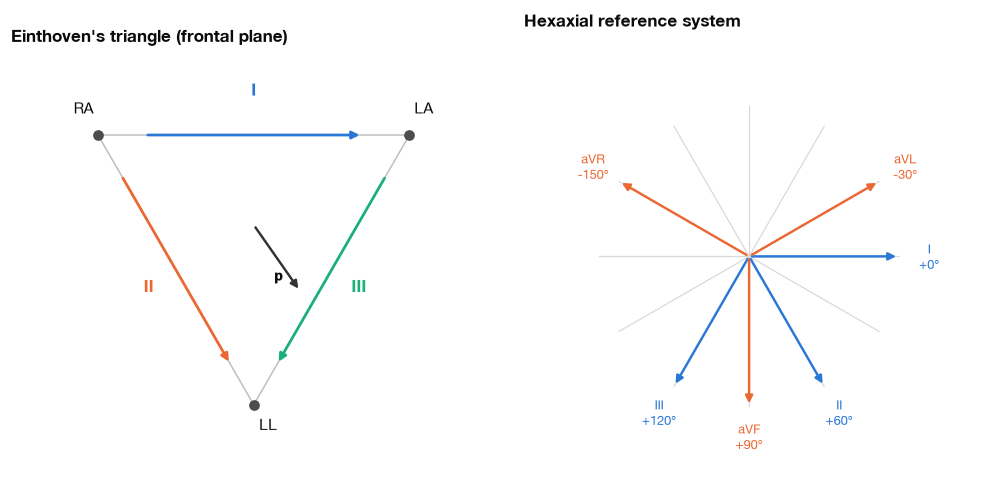

In [4]:
def card_xy(angle_deg, length=1.0):
    """Cartesian plot coordinates of a frontal-plane direction (cardiology convention)."""
    a = np.deg2rad(angle_deg)
    return length * np.cos(a), -length * np.sin(a)      # +90 deg points down (feet)


fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))
ax = axes[0]
corners = {"RA": card_xy(-150, 1.0), "LA": card_xy(-30, 1.0), "LL": card_xy(90, 1.0)}
tri = np.array([corners["RA"], corners["LA"], corners["LL"], corners["RA"]])
ax.plot(tri[:, 0], tri[:, 1], color="0.75", lw=1)
for name, (x, y) in corners.items():
    ax.plot(x, y, "o", color="0.3", ms=6)
    ax.text(x + 0.08 * np.sign(x), y + (0.12 if y > 0 else -0.14), name, ha="center", fontsize=10)
for (a, b, label), col in zip([("RA", "LA", "I"), ("RA", "LL", "II"), ("LA", "LL", "III")], C):
    (x0, y0), (x1, y1) = corners[a], corners[b]
    ax.annotate("", xy=(x0 + 0.85 * (x1 - x0), y0 + 0.85 * (y1 - y0)),
                xytext=(x0 + 0.15 * (x1 - x0), y0 + 0.15 * (y1 - y0)),
                arrowprops=dict(arrowstyle="-|>", color=col, lw=1.8))
    xm, ym = (x0 + x1) / 2, (y0 + y1) / 2
    ax.text(xm * 1.35, ym * 1.35 + (0.08 if label == "I" else 0), label, color=col,
            fontsize=11, fontweight="bold", ha="center", va="center")
ax.annotate("", xy=card_xy(55, 0.45), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color="0.2", lw=1.6))
ax.text(*card_xy(70, 0.33), r"$\mathbf{p}$", fontsize=11)
ax.set(xlim=(-1.35, 1.35), ylim=(-1.3, 0.95), title="Einthoven's triangle (frontal plane)")
ax.set_aspect("equal")
ax.axis("off")

ax = axes[1]
leads = {"I": 0, "II": 60, "III": 120, "aVR": -150, "aVL": -30, "aVF": 90}
for k, (name, ang) in enumerate(leads.items()):
    col = C[0] if k < 3 else C[1]
    xe, ye = card_xy(ang, 1.0)
    ax.plot([-xe, xe], [-ye, ye], color="0.85", lw=0.8)
    ax.annotate("", xy=(xe, ye), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
    xt, yt = card_xy(ang, 1.2)
    ax.text(xt, yt, f"{name}\n{ang:+d}°", ha="center", va="center", fontsize=8.5, color=col)
ax.set(xlim=(-1.5, 1.5), ylim=(-1.45, 1.45), title="Hexaxial reference system")
ax.set_aspect("equal")
ax.axis("off")
plt.show()

In the right panel, the limb leads are drawn in blue and the augmented leads in orange, each labeled with its direction. Angles are positive below the horizontal, following the cardiology convention; the direction "toward the feet" is $+90^\circ$.

(sec-11-1-4)=
## 11.1.4 A Rotating Dipole Seen Through Six Leads

Equation [(11.2)](#eq-11-2) turns ECG generation into a geometry exercise. When I first learned the lead system, what made it click was watching a single arrow rotate and seeing six leads respond to it, so we build exactly that. We build a schematic frontal-plane heart vector for one beat as three loops:

- a small **P loop** pointing down and to the left (about $+50^\circ$), peak 0.15 mV;
- a large, fast **QRS loop**. It starts with a small vector toward the right and down (about $+130^\circ$, the left-to-right septal activation), swings through the main direction near $+50^\circ$ (the left ventricular free wall, peak 1.2 mV) and ends pointing up and to the right (basal activation);
- a broad **T loop**, peak 0.35 mV, pointing near $+40^\circ$.

Each loop is a Gaussian amplitude envelope multiplied by a unit vector whose angle sweeps linearly through the wave. The numbers are chosen to resemble a normal adult ECG, not fitted to any recording. Projecting the vector onto the six frontal lead directions with equation [(11.5)](#eq-11-5) and its augmented-lead counterpart gives the six frontal leads.

In [5]:
fs_sim = 500                                  # Hz
t_sim = np.arange(0, 0.8, 1 / fs_sim)         # one beat at 75 bpm


def dipole_loop(t, t_c, width, peak, angle_start, angle_end):
    """Heart-vector loop: Gaussian amplitude, linearly sweeping angle (degrees)."""
    envelope = peak * np.exp(-0.5 * ((t - t_c) / width) ** 2)
    s = np.clip((t - t_c) / (2.5 * width), -1, 1)                  # -1 ... +1 across the wave
    angle = np.deg2rad(angle_start + (angle_end - angle_start) * (s + 1) / 2)
    return envelope * np.cos(angle), envelope * np.sin(angle)


loops = [(0.12, 0.022, 0.15, 60, 40),           # P
         (0.30, 0.012, 1.20, 140, -40),         # QRS: septal -> free wall -> base
         (0.56, 0.050, 0.35, 30, 50)]           # T
px = np.zeros_like(t_sim)
py = np.zeros_like(t_sim)
for loop in loops:
    dx, dy = dipole_loop(t_sim, *loop)
    px, py = px + dx, py + dy

lead_angles = {"I": 0, "II": 60, "III": 120, "aVR": -150, "aVL": -30, "aVF": 90}
lead_gain = {"I": 1, "II": 1, "III": 1, "aVR": np.sqrt(3) / 2, "aVL": np.sqrt(3) / 2, "aVF": np.sqrt(3) / 2}
sim = {name: lead_gain[name] * (px * np.cos(np.deg2rad(a)) + py * np.sin(np.deg2rad(a)))
       for name, a in lead_angles.items()}

print(f"max |I + III - II|          = {np.max(np.abs(sim['I'] + sim['III'] - sim['II'])):.2e} mV")
print(f"max |aVR + aVL + aVF|       = {np.max(np.abs(sim['aVR'] + sim['aVL'] + sim['aVF'])):.2e} mV")
print(f"max |aVF - (II + III)/2|    = {np.max(np.abs(sim['aVF'] - (sim['II'] + sim['III']) / 2)):.2e} mV")
qrs = (t_sim > 0.25) & (t_sim < 0.35)
mean_axis = np.rad2deg(np.arctan2(py[qrs].sum(), px[qrs].sum()))
print(f"mean QRS axis of the model  = {mean_axis:+.1f} deg")

max |I + III - II|          = 2.22e-16 mV
max |aVR + aVL + aVF|       = 2.22e-16 mV
max |aVF - (II + III)/2|    = 2.22e-16 mV
mean QRS axis of the model  = +50.0 deg


The three identities hold to machine precision, as they must, because they are consequences of linear algebra rather than of the particular loop we drew.

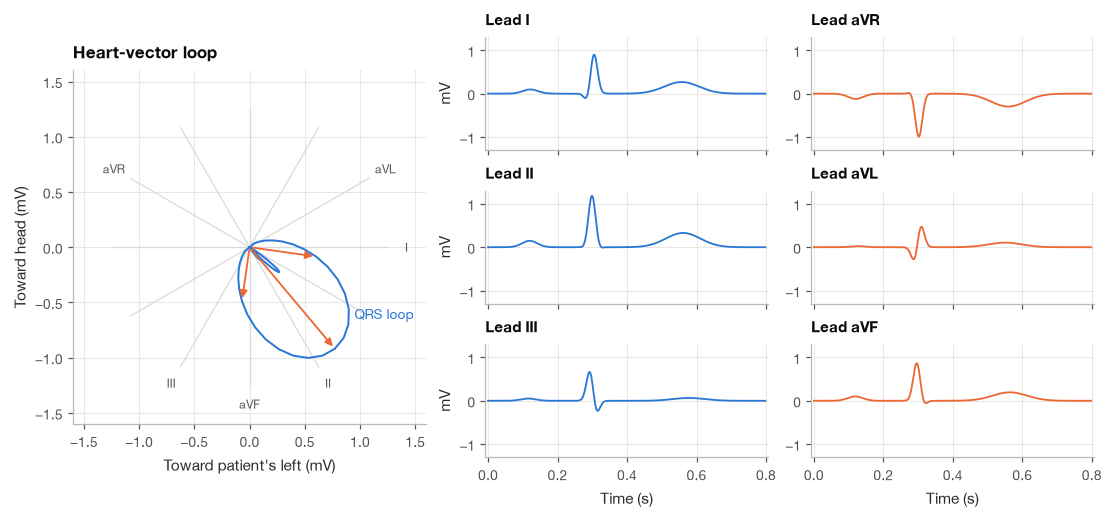

In [6]:
fig = plt.figure(figsize=(10, 4.6))
gs = fig.add_gridspec(3, 3, width_ratios=[1.25, 1, 1])
ax = fig.add_subplot(gs[:, 0])
for name, ang in lead_angles.items():
    xe, ye = card_xy(ang, 1.25)
    ax.plot([-xe, xe], [-ye, ye], color="0.85", lw=0.8)
    xt, yt = card_xy(ang, 1.42)
    ax.text(xt, yt, name, ha="center", va="center", fontsize=8, color="0.35")
ax.plot(px, -py, color=C[0], lw=1.3)
for t_mark in (0.285, 0.30, 0.315):
    i = int(t_mark * fs_sim)
    ax.annotate("", xy=(px[i], -py[i]), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=C[1], lw=1.2))
ax.text(0.95, -0.65, "QRS loop", color=C[0], fontsize=9)
ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), xlabel="Toward patient's left (mV)",
       ylabel="Toward head (mV)", title="Heart-vector loop")
ax.set_aspect("equal")

for k, name in enumerate(["I", "II", "III", "aVR", "aVL", "aVF"]):
    ax = fig.add_subplot(gs[k % 3, 1 + k // 3])
    ax.plot(t_sim, sim[name], color=C[0] if k < 3 else C[1], lw=1.2)
    ax.set_ylim(-1.3, 1.3)
    ax.set_title(f"Lead {name}", fontsize=10)
    if k % 3 == 2:
        ax.set_xlabel("Time (s)")
    else:
        ax.set_xticklabels([])
    if k < 3:
        ax.set_ylabel("mV")
plt.show()

The left panel shows the QRS loop traced counterclockwise from the septal vector, with three instantaneous vectors drawn in orange near the peak. On the right, leads I, II and aVF show tall R waves because the main vector at $+50^\circ$ lies close to their directions; aVR, which looks from $-150^\circ$, sees the same events almost head-on from behind and shows an inverted complex. Lead I shows a small initial negative deflection, the septal q wave, because the first part of the loop points to the right. Lead III, nearly perpendicular to the initial and terminal vectors, shows a more complex shape. This is how clinicians read the frontal-plane **electrical axis** at a glance, by finding the lead with the largest positive QRS and the lead in which the QRS is nearly balanced (perpendicular to the axis).

(sec-11-1-5)=
## 11.1.5 Waves, Intervals and Normal Values

### A labeled beat

Real ECGs are messier than the simulation, and their features have conventional names that every later section relies on. The figure below shows one beat from MIT-BIH record 100 (modified lead II, 360 Hz). We locate the wave peaks with simple windowed searches around the annotated R peak, and the onsets and offsets with crude amplitude and slope rules; more careful delineation is the subject of Section 19.3.

In [7]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=30 * 360, channels=[0])
fs = rec.fs
ecg = rec.p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=30 * 360)
beats = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym == "N"])

b_lp, a_lp = signal.butter(2, 40, fs=fs)
ecg_smooth = signal.filtfilt(b_lp, a_lp, ecg)          # 40 Hz zero-phase low-pass for fiducials


def ms(x_ms):
    """Convert milliseconds to samples at the record's sampling rate."""
    return int(round(x_ms * fs / 1000))


r = beats[10]
r_next = beats[11]
baseline = np.median(ecg_smooth[r - ms(80):r - ms(50)])     # PR segment level
x = ecg_smooth - baseline
dx = np.gradient(x) * fs                                     # mV/s

p_peak = r - ms(260) + np.argmax(x[r - ms(260):r - ms(100)])
q_pt = r - ms(60) + np.argmin(x[r - ms(60):r])
s_pt = r + np.argmin(x[r:r + ms(60)])
t_peak = r + ms(150) + np.argmax(x[r + ms(150):r + ms(450)])

slope_thr = 0.05 * np.max(np.abs(dx[r - ms(60):r + ms(60)]))
qrs_on = r - ms(80) + np.argmin(dx[r - ms(80):q_pt])         # steepest down-slope into Q
while abs(dx[qrs_on]) > slope_thr:                            # walk back until the slope flattens
    qrs_on -= 1
qrs_off = s_pt + np.argmax(dx[s_pt:s_pt + ms(60)])            # steepest up-slope out of S
while abs(dx[qrs_off]) > slope_thr:
    qrs_off += 1
p_on = p_peak
while x[p_on] > 0.1 * x[p_peak]:
    p_on -= 1
k = t_peak + np.argmin(dx[t_peak:t_peak + ms(150)])          # steepest descent of the T wave
t_end = k + int(round(-x[k] / dx[k] * fs))                   # tangent meets the baseline

to_ms = lambda n: 1000 * (n - r) / fs
print(f"PR interval  : {1000 * (qrs_on - p_on) / fs:5.0f} ms")
print(f"QRS duration : {1000 * (qrs_off - qrs_on) / fs:5.0f} ms")
print(f"QT interval  : {1000 * (t_end - qrs_on) / fs:5.0f} ms")
print(f"RR interval  : {1000 * (r_next - r) / fs:5.0f} ms  ->  {60 * fs / (r_next - r):.1f} bpm")
print(f"Amplitudes   : P {x[p_peak]:.2f} mV, R {x[r]:.2f} mV, T {x[t_peak]:.2f} mV")

PR interval  :   175 ms
QRS duration :    81 ms
QT interval  :   486 ms
RR interval  :   772 ms  ->  77.7 bpm
Amplitudes   : P 0.14 mV, R 1.04 mV, T 0.07 mV


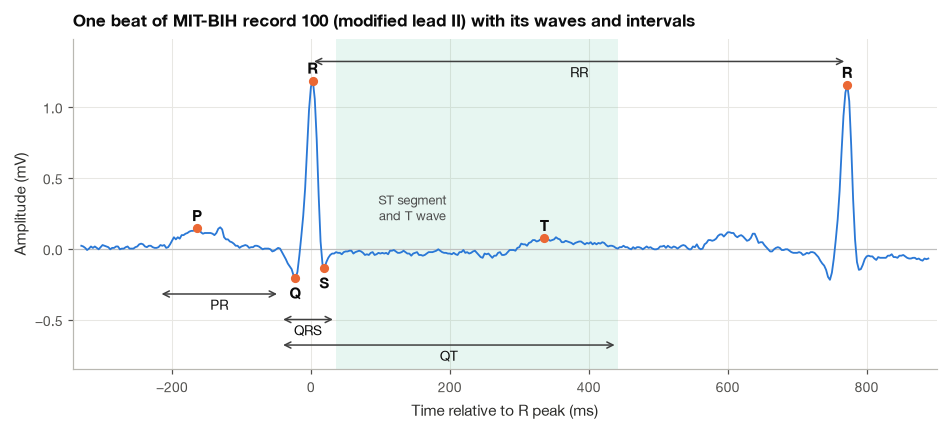

In [8]:
win = slice(r - ms(330), r_next + ms(120))
tt = 1000 * (np.arange(win.start, win.stop) - r) / fs
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.axhline(0, color="0.75", lw=0.8)
ax.plot(tt, ecg[win] - baseline, color=C[0], lw=1.2)
raw = ecg - baseline
for n, label, dy in [(p_peak, "P", 0.09), (q_pt, "Q", -0.1), (r, "R", 0.09), (s_pt, "S", -0.1),
                     (t_peak, "T", 0.09), (r_next, "R", 0.09)]:
    n_raw = n - ms(8) + np.argmax(raw[n - ms(8):n + ms(8)] * np.sign(dy))   # marker on the raw trace
    ax.plot(to_ms(n_raw), raw[n_raw], "o", color=C[1], ms=5)
    ax.text(to_ms(n_raw), raw[n_raw] + dy, label, ha="center", va="center", fontsize=10, fontweight="bold")


def interval_bar(n0, n1, y, label):
    ax.annotate("", xy=(to_ms(n1), y), xytext=(to_ms(n0), y),
                arrowprops=dict(arrowstyle="<->", color="0.25", lw=1))
    ax.text((to_ms(n0) + to_ms(n1)) / 2, y - 0.075, label, ha="center", va="center", fontsize=9)


interval_bar(p_on, qrs_on, -0.32, "PR")
interval_bar(qrs_on, qrs_off, -0.50, "QRS")
interval_bar(qrs_on, t_end, -0.68, "QT")
interval_bar(r, r_next, 1.32, "RR")
ax.axvspan(to_ms(qrs_off), to_ms(t_end), color=C[2], alpha=0.10, lw=0)
ax.text((to_ms(qrs_off) + to_ms(t_peak)) / 2 - 40, 0.2, "ST segment\nand T wave", ha="center",
        fontsize=8.5, color="0.3")
ax.set(xlabel="Time relative to R peak (ms)", ylabel="Amplitude (mV)", ylim=(-0.85, 1.48),
       title="One beat of MIT-BIH record 100 (modified lead II) with its waves and intervals")
plt.show()

The PR interval (175 ms) and the QRS duration (81 ms) of this beat are unremarkable. The QT interval is another matter. The T wave in this lead is very low (about 0.1 mV) and broad, and it is preceded by a long, nearly flat segment, so it is not even obvious whether the hump around 340 ms is the whole T wave, the late part of a biphasic T wave, or a U wave following a flat T. Taken at face value, a QT of 486 ms at an RR interval of 0.77 s would be long, but the end of such a wave is uncertain by tens of milliseconds and the identity of the wave itself is in doubt. Low-amplitude T waves are common in single ambulatory leads, and they are precisely the case in which automatic QT measurements are least reliable; a clinician would measure QT on a 12-lead recording, in the leads where the T wave is best defined. We return to this in Section 19.3. For now the lesson is that a number printed by an algorithm is only as trustworthy as the fiducial point behind it.

### Normal ranges

The table lists commonly quoted reference ranges for the resting adult ECG. They are guides, not hard limits: normal values depend on age, sex, heart rate, the lead used and the measurement method, and published limits differ slightly between sources {cite:p}`kligfield2007,sornmo2005,clifford2006`.

| Feature | What it measures | Typical adult range |
|---|---|---|
| Heart rate (sinus rhythm, rest) | SA node rate | about 60–100 bpm |
| RR interval | time between consecutive R peaks | about 0.6–1.0 s at those rates |
| P wave | atrial depolarization | duration < 120 ms; amplitude < 0.25 mV in lead II |
| PR interval | P onset to QRS onset (atrial activation plus AV delay) | 120–200 ms |
| QRS duration | ventricular depolarization | about 70–100 ms; ≥ 120 ms indicates abnormal intraventricular conduction |
| ST segment | ventricular plateau | close to the PR baseline; deviations around 0.1 mV or more are assessed with lead-, age- and sex-specific criteria |
| T wave | ventricular repolarization | upright in I, II and V3–V6; inverted in aVR |
| QT interval | QRS onset to T end (total ventricular activity) | strongly rate dependent; judged after rate correction |
| QTc (rate corrected) | QT normalized to 60 bpm | upper limits of roughly 450 ms (men) and 460 ms (women) |
| Frontal QRS axis | mean direction of $\mathbf{p}$ during QRS | about $-30^\circ$ to $+90^\circ$ |

### Heart rate from RR intervals

If two consecutive R peaks are separated by $\mathrm{RR}$ seconds, the instantaneous heart rate is

(eq-11-9)=
\begin{equation*}
\mathrm{HR} = \frac{60}{\mathrm{RR}} \quad \text{(beats per minute)}. \tag{11.9}
\end{equation*}

On standard ECG paper, printed at 25 mm/s with a gain of 10 mm/mV, one small 1 mm box is 40 ms and 0.1 mV and one large 5 mm box is 200 ms and 0.5 mV. An RR interval of $n$ large boxes therefore lasts $0.2n$ s, and $\mathrm{HR} = 60/(0.2n) = 300/n$, the bedside rule "300 divided by the number of big boxes."

Equation [(11.9)](#eq-11-9) is nonlinear, so the average of instantaneous heart rates is not the heart rate of the average RR interval. For RR intervals of 0.6 s and 1.0 s the instantaneous rates are 100 and 60 bpm, whose mean is 80 bpm, while the mean RR of 0.8 s corresponds to 75 bpm. The difference is small for a steady rhythm and large for an irregular one, so we always state which average we report.

### Rate correction of the QT interval

The ventricular action potential shortens when the heart beats faster, so the QT interval shrinks as the RR interval shortens. To compare QT values recorded at different heart rates, the QT is "corrected" to what it would be at 60 bpm ($\mathrm{RR} = 1$ s). Bazett's empirical formula assumes that QT grows with the square root of RR:

(eq-11-10)=
\begin{equation*}
\mathrm{QT} \approx \mathrm{QTc}\,\sqrt{\mathrm{RR}/(1\ \text{s})}
\quad\Longrightarrow\quad
\mathrm{QTc}_{\text{B}} = \frac{\mathrm{QT}}{\sqrt{\mathrm{RR}/(1\ \text{s})}}. \tag{11.10}
\end{equation*}

Dividing RR by one second keeps the units of QTc equal to those of QT; textbooks often write simply $\mathrm{QT}/\sqrt{\mathrm{RR}}$ with RR in seconds.

**Example 11.1.1.** A patient has QT = 360 ms at 75 bpm. Find the Bazett-corrected QT, and repeat for QT = 300 ms at 120 bpm.

At 75 bpm, equation [(11.9)](#eq-11-9) gives $\mathrm{RR} = 60/75 = 0.8$ s, so $\mathrm{QTc} = 360/\sqrt{0.8} = 360/0.894 = 402$ ms. At 120 bpm, $\mathrm{RR} = 0.5$ s and $\mathrm{QTc} = 300/\sqrt{0.5} = 300/0.707 = 424$ ms. Although the raw QT dropped by 60 ms, the corrected value went *up*. Bazett's formula is known to overcorrect at high heart rates and undercorrect at low ones, which is why alternatives such as Fridericia's cube-root formula, $\mathrm{QTc}_{\text{F}} = \mathrm{QT}/\sqrt[3]{\mathrm{RR}}$, are often preferred in drug-safety studies. Bazett's formula remains the most widely reported, so we use it here and keep its bias in mind.

In [9]:
def qtc_bazett(qt_ms, rr_s):
    """Bazett-corrected QT (ms), equation (17.10)."""
    return qt_ms / np.sqrt(rr_s)


def qtc_fridericia(qt_ms, rr_s):
    """Fridericia-corrected QT (ms)."""
    return qt_ms / np.cbrt(rr_s)


for qt, hr in [(360, 75), (300, 120)]:
    rr = 60 / hr
    print(f"QT = {qt} ms at {hr:3d} bpm (RR = {rr:.2f} s): "
          f"Bazett {qtc_bazett(qt, rr):.0f} ms, Fridericia {qtc_fridericia(qt, rr):.0f} ms")

QT = 360 ms at  75 bpm (RR = 0.80 s): Bazett 402 ms, Fridericia 388 ms
QT = 300 ms at 120 bpm (RR = 0.50 s): Bazett 424 ms, Fridericia 378 ms


Fridericia's correction gives 388 ms and 378 ms for the two cases, much closer to each other than Bazett's 402 and 424 ms.

(sec-11-1-6)=
## 11.1.6 Checking the Lead Relations on Real Monitor Data

Equations [(11.4)](#eq-11-4) and [(11.8)](#eq-11-8) are easy to accept on paper. I find them far more convincing once they have been tested on a real recording, and the BIDMC PPG and Respiration Dataset {cite:p}`pimentel2017,goldberger2000` lets us do exactly that. It contains 8-minute recordings from intensive care patients, sampled at 125 Hz, and each record includes ECG lead II and lead aVR from the bedside monitor (plus one chest lead labeled V), but not lead I or lead III. Equation [(11.8)](#eq-11-8) lets us reconstruct the missing leads. Solving $\text{aVR} = -(\text{I} + \text{II})/2$ for lead I and then using Einthoven's law [(11.4)](#eq-11-4),

(eq-11-11)=
\begin{equation*}
\text{I} = -2\,\text{aVR} - \text{II}, \qquad \text{III} = \text{II} - \text{I} = 2\,\text{II} + 2\,\text{aVR}. \tag{11.11}
\end{equation*}

The derivation relies on four assumptions, and I want to state them plainly. First, the monitor computes aVR with Goldberger's definition from the same three limb electrodes used for lead II. Second, both channels have the same gain and the same filtering and are sampled simultaneously; since [(11.11)](#eq-11-11) is linear, identical linear filtering of both inputs does no harm. Third, the constant offsets present in the exported files carry no physiological meaning, so we may remove them together with baseline drift. Fourth, the electrodes were placed correctly. None of these can be verified from the files alone, so the reconstruction is a consistency check rather than a measurement of leads I and III.

### Step 1: Load leads II and aVR and remove the offsets

The channel order differs between BIDMC records, so we select channels by name (the names carry a trailing comma). A zero-phase 0.5–40 Hz Butterworth band-pass removes the offsets and the baseline drift without shifting the waves in time; the design choices behind such a filter are the subject of [Section 12.2](../ch18_ecg_preprocessing/index.md), and zero-phase filtering itself is covered in Section 15.3.

In [10]:
def load_ii_avr(name, band=(0.5, 40.0)):
    """Load leads II and aVR from a BIDMC record and band-pass them with a zero-phase filter."""
    rec = wfdb.rdrecord(f"../data/bidmc/{name}")
    names = [s.strip(",") for s in rec.sig_name]
    b, a = signal.butter(2, band, btype="bandpass", fs=rec.fs)
    lead_ii = signal.filtfilt(b, a, rec.p_signal[:, names.index("II")])
    avr = signal.filtfilt(b, a, rec.p_signal[:, names.index("AVR")])
    return lead_ii, avr, rec.fs


raw_offsets = {}
for name in ["bidmc01", "bidmc02", "bidmc03"]:
    rec = wfdb.rdrecord(f"../data/bidmc/{name}", sampto=1250)
    names = [s.strip(",") for s in rec.sig_name]
    raw_offsets[name] = [np.median(rec.p_signal[:, names.index(ch)]) for ch in ("II", "AVR")]
print("Median raw value of each channel (mV), before filtering:")
for name, (off_ii, off_avr) in raw_offsets.items():
    print(f"  {name}: II {off_ii:+.2f}   aVR {off_avr:+.2f}")

Median raw value of each channel (mV), before filtering:
  bidmc01: II +0.38   aVR +0.53
  bidmc02: II +0.22   aVR +0.69
  bidmc03: II +0.44   aVR +0.44


The offsets of several tenths of a millivolt are an artifact of the export, not cardiac signals; they would otherwise be multiplied by $-2$ in [(11.11)](#eq-11-11) and appear as a large constant in lead I.

### Step 2: Derive leads I, III, aVL and aVF

Equation [(11.11)](#eq-11-11) gives leads I and III, and [(11.8)](#eq-11-8) then gives the two remaining augmented leads. Each line of the function below implements one equation.

In [11]:
def derive_frontal_leads(lead_ii, avr):
    """All six frontal leads from II and aVR, equations (17.11), (17.4) and (17.8)."""
    lead_i = -2 * avr - lead_ii
    lead_iii = lead_ii - lead_i
    return {"I": lead_i, "II": lead_ii, "III": lead_iii,
            "aVR": avr, "aVL": (lead_i - lead_iii) / 2, "aVF": (lead_ii + lead_iii) / 2}


bidmc = {}
for name in ["bidmc01", "bidmc02", "bidmc03"]:
    lead_ii, avr, fs_b = load_ii_avr(name)
    bidmc[name] = derive_frontal_leads(lead_ii, avr)
leads = bidmc["bidmc01"]
print(f"max |aVR + aVL + aVF| = {np.max(np.abs(leads['aVR'] + leads['aVL'] + leads['aVF'])):.1e} mV "
      "(zero by construction)")

max |aVR + aVL + aVF| = 2.2e-16 mV (zero by construction)


The printed identity is a sanity check on the code, not on the data: once leads I and III have been built from II and aVR, the augmented leads must sum to zero.

### Step 3: Look at the derived leads

The real test is whether the derived leads look like electrocardiograms. We plot four seconds of the two recorded leads (blue) and the two derived leads (orange) for each patient.

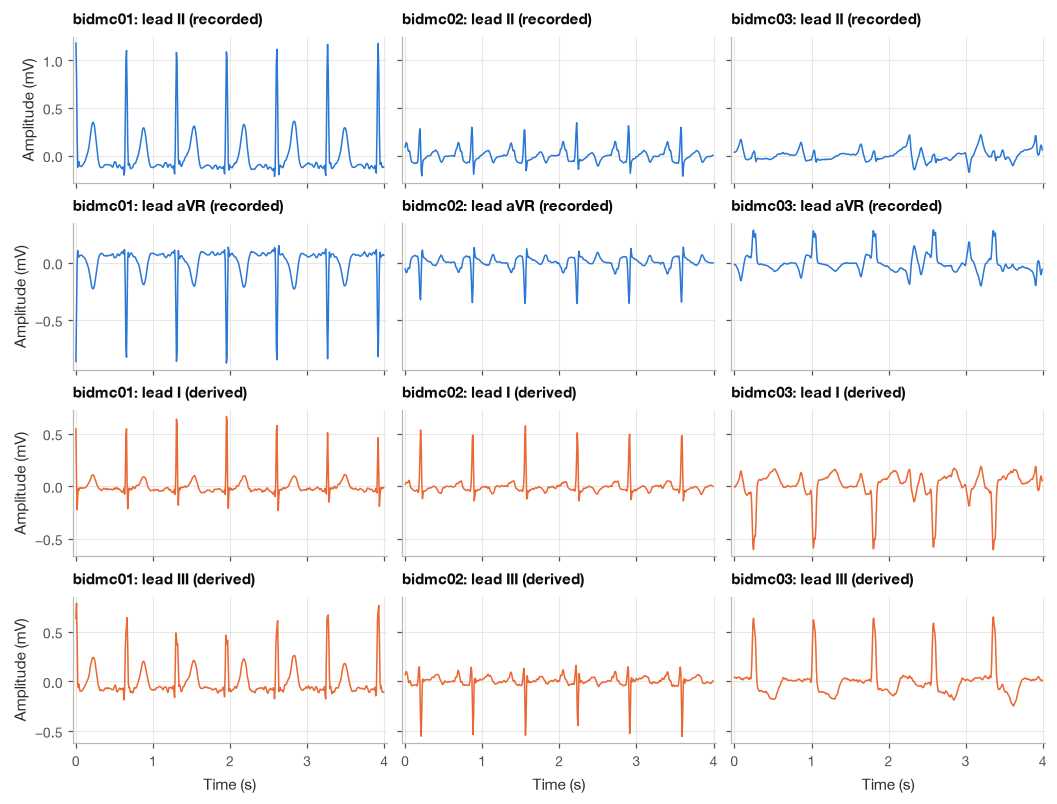

In [12]:
t0, dur = 100.0, 4.0
seg = slice(int(t0 * fs_b), int((t0 + dur) * fs_b))
tb = np.arange(seg.stop - seg.start) / fs_b
rows_plot = [("II", "recorded", C[0]), ("aVR", "recorded", C[0]),
             ("I", "derived", C[1]), ("III", "derived", C[1])]
fig, axes = plt.subplots(4, 3, figsize=(9.5, 7.2), sharex=True, sharey="row")
for j, name in enumerate(bidmc):
    for i, (lead, kind, col) in enumerate(rows_plot):
        ax = axes[i, j]
        ax.plot(tb, bidmc[name][lead][seg], color=col, lw=1)
        ax.set_title(f"{name}: lead {lead} ({kind})", fontsize=9.5)
        if j == 0:
            ax.set_ylabel("Amplitude (mV)")
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
plt.show()

The derived leads have sharp QRS complexes, T waves and an isoelectric baseline, with no trace of the subtraction other than slightly more noise (lead I combines two noisy channels with weights $-2$ and $-1$, so uncorrelated noise grows by a factor $\sqrt{5}$). The three patients also differ in an informative way. In bidmc01 the QRS is positive in I, II and III, a normal pattern with a fairly vertical axis. In bidmc02 lead I is clearly positive while lead III is dominated by a deep negative deflection, which suggests a leftward axis. In bidmc03 the derived lead I is mostly *negative* and aVR is positive.

### Step 4: Turn the impressions into a QRS axis

Combining [(11.5)](#eq-11-5) and [(11.8)](#eq-11-8), lead I measures $|\mathbf{p}|\cos\theta$ and aVF measures $\tfrac{\sqrt{3}}{2}|\mathbf{p}|\sin\theta$, so the mean frontal QRS axis is

(eq-11-12)=
\begin{equation*}
\theta_{\text{QRS}} = \operatorname{atan2}\!\left(\frac{2}{\sqrt{3}}\,A_{\text{aVF}},\; A_{\text{I}}\right), \tag{11.12}
\end{equation*}

where $A$ is the net area of the QRS complex (positive minus negative parts) in the averaged beat. We locate the beats with a simple peak search on the vector magnitude, average them (the noise-reduction argument is in [Section 10.1](../ch16_noise_removal/index.md)) and integrate from 50 ms before to 70 ms after each peak, measuring the area relative to the level 80 to 120 ms before the peak.

In [13]:
def qrs_axis(leads, fs):
    """Mean frontal QRS axis (degrees) from net QRS areas in leads I and aVF, equation (17.12)."""
    magnitude = np.hypot(leads["I"], 2 * leads["aVF"] / np.sqrt(3))
    peaks, _ = signal.find_peaks(magnitude, distance=int(0.35 * fs),
                                 height=0.4 * np.percentile(magnitude, 99))
    peaks = peaks[(peaks > int(0.2 * fs)) & (peaks < magnitude.size - int(0.2 * fs))]
    qrs = np.arange(-int(0.05 * fs), int(0.07 * fs) + 1)
    pre = np.arange(-int(0.12 * fs), -int(0.08 * fs))
    areas = {}
    for lead in ("I", "aVF"):
        x = leads[lead]
        avg = np.mean([x[p + qrs] for p in peaks], axis=0)
        base = np.mean([x[p + pre] for p in peaks])
        areas[lead] = np.sum(avg - base) / fs * 1000           # mV ms
    theta = np.rad2deg(np.arctan2(2 * areas["aVF"] / np.sqrt(3), areas["I"]))
    return theta, areas, len(peaks)


rows = []
for name, leads in bidmc.items():
    theta, areas, n_beats = qrs_axis(leads, fs_b)
    rows.append([name, n_beats, areas["I"], areas["aVF"], theta])
axis_table = pd.DataFrame(rows, columns=["record", "beats", "area I (mV ms)", "area aVF (mV ms)", "axis (deg)"])
print(axis_table.round(1).to_string(index=False))

 record  beats  area I (mV ms)  area aVF (mV ms)  axis (deg)
bidmc01    730             7.6              27.5        76.5
bidmc02    727             9.5               3.8        24.6
bidmc03    612           -24.8              14.7       145.6


The estimated axes are about $+77^\circ$ for bidmc01 and $+25^\circ$ for bidmc02, both within the conventional normal range of $-30^\circ$ to $+90^\circ$ (the visual impression of a "leftward" axis in bidmc02 came from the deep but narrow negative deflection in lead III, which contributes less area than its height suggests). For bidmc03 the axis is about $+146^\circ$, far to the right. On a clinical ECG, a negative lead I together with a positive aVR has two common explanations that these two leads cannot separate: genuine right-axis deviation, or left and right arm electrodes swapped during placement, a frequent technical error. I do not try to decide between them from these files. The point is that equation [(11.11)](#eq-11-11) produced physiologically sensible waveforms in all three records, and that simple vector arithmetic already flags a recording that a careful reader would want to double-check.

(sec-11-1-7)=
## 11.1.7 A First Look at Abnormal Rhythms

Everything so far assumed a normal beat starting in the SA node. The MIT-BIH Arrhythmia Database {cite:p}`moody2001` contains half-hour two-channel recordings annotated beat by beat by cardiologists: each R peak carries a label (`N` normal, `V` premature ventricular contraction, `F` fusion, `A` atrial premature beat and others), and rhythm changes such as `(AFIB` or `(B` (bigeminy) appear in a separate text field. [Section 11.3](03_ecg_data_in_python.ipynb) shows how to read these files and how the ECG-paper grid used below is drawn; here I only want to connect a few abnormal shapes to the physiology of Section 11.1.1.

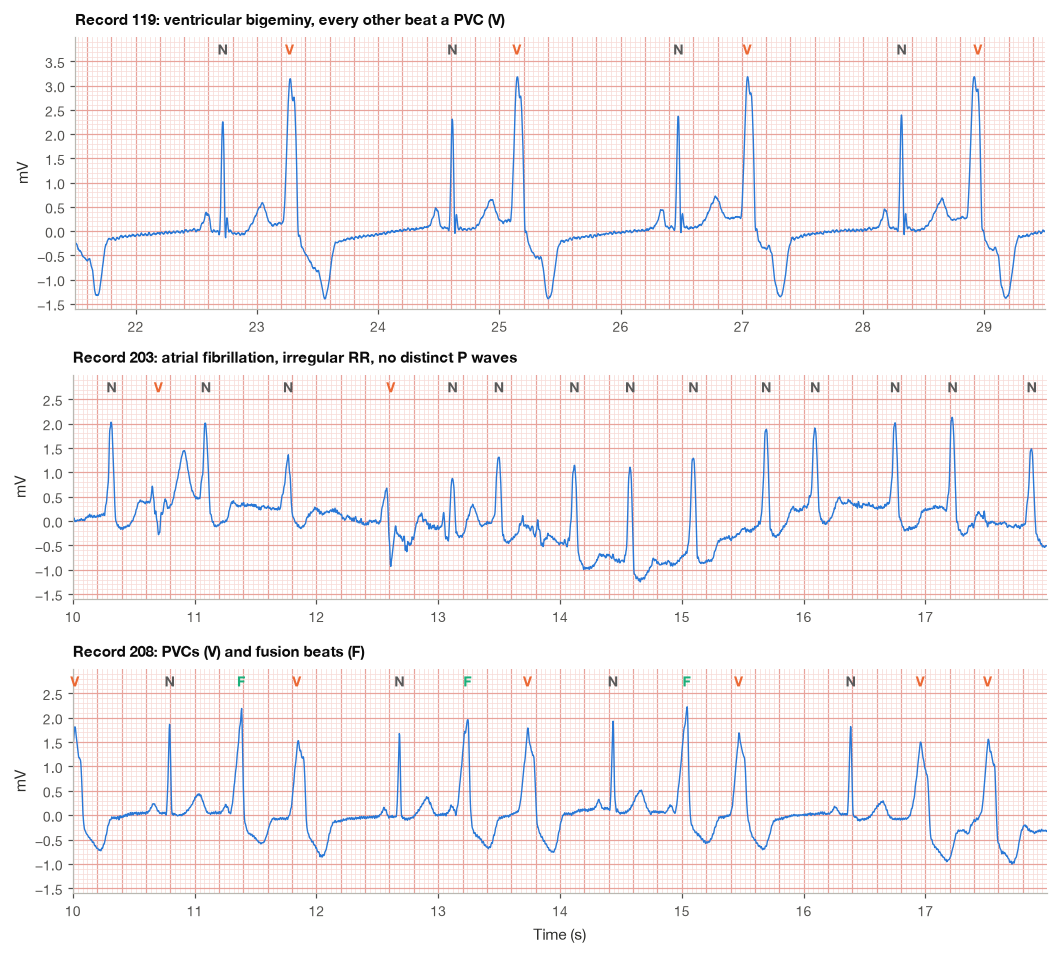

In [14]:
def ecg_paper(ax, t_start, t_stop, v_min, v_max):
    """Standard ECG grid (40 ms x 0.1 mV small boxes) with the 25 mm/s, 10 mm/mV aspect ratio."""
    for xg in np.arange(np.ceil(t_start / 0.04) * 0.04, t_stop, 0.04):
        major = abs(xg / 0.2 - round(xg / 0.2)) < 1e-6
        ax.axvline(xg, color="#e8a39b" if major else "#f8dcd8", lw=0.8 if major else 0.5, zorder=0)
    for yg in np.arange(np.ceil(v_min / 0.1) * 0.1, v_max, 0.1):
        major = abs(yg / 0.5 - round(yg / 0.5)) < 1e-6
        ax.axhline(yg, color="#e8a39b" if major else "#f8dcd8", lw=0.8 if major else 0.5, zorder=0)
    ax.grid(False)
    ax.set(xlim=(t_start, t_stop), ylim=(v_min, v_max))
    ax.set_aspect(0.4)                       # 10 mm per mV / 25 mm per s


def rhythm_strip(ax, record, t_start, duration, title):
    """Plot an MLII strip from an MIT-BIH record with its beat labels on ECG paper."""
    path = f"../data/mitdb/{record}"
    n0, n1 = int(t_start * 360), int((t_start + duration) * 360)
    rec = wfdb.rdrecord(path, sampfrom=n0, sampto=n1, channels=[0])
    ann = wfdb.rdann(path, "atr", sampfrom=n0, sampto=n1)
    t = t_start + np.arange(rec.sig_len) / rec.fs
    x = rec.p_signal[:, 0] - np.median(rec.p_signal[:, 0])
    v_range = (np.floor(x.min() / 0.5) * 0.5 - 0.1, np.ceil(x.max() / 0.5) * 0.5 + 0.5)
    ecg_paper(ax, t[0], t[-1], *v_range)
    ax.plot(t, x, color=C[0], lw=0.9, zorder=2)
    colors = {"N": "0.35", "V": C[1], "F": C[2], "A": C[4]}
    for s, sym in zip(ann.sample, ann.symbol):
        if sym in colors:
            ax.text(s / 360, v_range[1] - 0.25, sym, ha="center", va="center", fontsize=9,
                    color=colors[sym], fontweight="bold")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("mV")
    ax.set_yticks(np.arange(np.ceil(v_range[0] / 0.5) * 0.5, v_range[1], 0.5))


strips = [("119", 21.5, "Record 119: ventricular bigeminy, every other beat a PVC (V)"),
          ("203", 10.0, "Record 203: atrial fibrillation, irregular RR, no distinct P waves"),
          ("208", 10.0, "Record 208: PVCs (V) and fusion beats (F)")]
fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.6))
for ax, (record, t_start, title) in zip(axes, strips):
    rhythm_strip(ax, record, t_start, 8.0, title)
axes[-1].set_xlabel("Time (s)")
plt.show()

A **premature ventricular contraction** (PVC, record 119) starts in a ventricular focus instead of the sinus node. It arrives early, has no preceding P wave and, because it spreads through ordinary muscle rather than the fast Purkinje network, produces a wide complex followed by a T wave of opposite polarity; when every other beat is a PVC the pattern is called **bigeminy**. In **atrial fibrillation** (record 203) the atria are activated chaotically, so there is no organized P wave, and the AV node passes impulses at random times, making the RR intervals "irregularly irregular." A **fusion beat** (record 208) occurs when an ectopic ventricular focus fires just as a sinus impulse arrives through the conduction system; the ventricles are activated partly from each source and the complex looks intermediate between a normal beat and a PVC. Section 19.4 turns these descriptions into measurable features and a simple atrial fibrillation detector.

```{note}
The beat labels and rhythm descriptions in this section are for teaching signal processing. Diagnosing arrhythmias requires multi-lead recordings, clinical context and trained interpretation; a single strip is never sufficient on its own.
```

## Summary

The ECG is the body-surface footprint of a wave of depolarization that starts in the SA node, pauses in the AV node, races through the His–Purkinje system and activates the ventricles within about a tenth of a second. Because cells only produce external fields while a boundary between active and resting tissue exists, the P wave, QRS complex and T wave map onto atrial depolarization, ventricular depolarization and ventricular repolarization. Summarizing the active wavefront as a current dipole $\mathbf{p}(t)$ in a linear volume conductor leads to the central result $V = \mathbf{p}\cdot\mathbf{l}$: every lead is a projection of the same heart vector. From it, and from the definitions of the electrode combinations, we derived Einthoven's law $\text{II} = \text{I} + \text{III}$, Wilson's central terminal as the average limb potential and Goldberger's augmented leads. We then used these relations to reconstruct leads I and III from the II and aVR channels of real bedside monitor data and to estimate each patient's QRS axis, and we met three common departures from normal rhythm.

The next two sections stay close to the hardware and the files. [Section 11.2](02_recording_the_ecg.ipynb) follows the signal from the electrode through the amplifier and the anti-aliasing filter to the analog-to-digital converter, and [Section 11.3](03_ecg_data_in_python.ipynb) shows how the resulting PhysioNet records and annotations are read and plotted in Python. [Chapter 12](../ch18_ecg_preprocessing/index.md) removes noise, and Chapter 19 detects beats, measures heart rate variability, describes beat morphology and analyzes rhythm. The dipole model reappears in Chapter 25, where the linear mixing of a few sources into many electrodes is exactly the assumption behind principal and independent component analysis.

## Exercises

1. Starting from the definitions [(11.3)](#eq-11-3) and the Goldberger formulas, show that $\text{aVL} = (\text{I} - \text{III})/2$ and $\text{aVF} = (\text{II} + \text{III})/2$, and verify that $\text{aVR} + \text{aVL} + \text{aVF} = 0$.
2. An ECG shows a QRS complex whose net area is $+6$ mV·ms in lead I and $-6$ mV·ms in aVF. Use equation [(11.12)](#eq-11-12) to compute the frontal QRS axis and state whether it lies inside the conventional normal range.
3. Show that in the ideal Einthoven model the Wilson central terminal potential is zero at every instant. (Hint: write the three limb potentials as projections of $\mathbf{p}$ onto unit vectors at $-150^\circ$, $-30^\circ$ and $+90^\circ$ and add them.)
4. A patient's QT interval is 420 ms at a heart rate of 50 bpm and 340 ms at 100 bpm. Compute QTc with both Bazett's and Fridericia's formulas at each rate and comment on which correction gives more consistent values.
5. Modify the rotating-dipole simulation so that the main QRS vector points to $-45^\circ$ (left-axis deviation). Predict, before running the code, which of the six frontal leads will show the largest positive and the largest negative QRS, then check your prediction and estimate the axis with equation [(11.12)](#eq-11-12).
6. In record 119, find each PVC (label `V`) preceded and followed by a normal beat, and measure the RR interval before it (the coupling interval) and after it (the pause). Check how close the sum of the two is to twice the median normal RR interval, and explain from the conduction physiology of [Section 11.1.1](#sec-11-1-1) why a ventricular ectopic beat usually leaves the sinus rhythm undisturbed.

## Further Reading

{cite:t}`malmivuo1995` develop the volume-conductor theory of the ECG, lead vectors, the Burger triangle and the derivation of the standard leads in far more depth than we could here, and the book is freely available online. {cite:t}`plonsey2007` give a quantitative account of cardiac action potentials and their extracellular fields. The technical standards for ECG leads, electrode placement and recording bandwidth are set out by {cite:t}`kligfield2007`, and {cite:t}`clifford2006` and {cite:t}`sornmo2005` connect ECG physiology with the signal processing methods developed in the rest of this chapter.